In [1]:
%pip install torch torchvision shap opencv-python matplotlib pandas numpy pillow


   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   --------------------------- ----------- 524.3/751.9 kB 10.1 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 7.6 MB/s eta 0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [9]:
def inspect_checkpoint(path):
    path = Path(path)

    if not path.exists():
        print(f"\nCheckpoint not found: {path}")
        return

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print(f"\nCheckpoint: {path.name}")
    print("Type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys())[:20])

        state_dict = checkpoint.get(
            "state_dict",
            checkpoint.get(
                "model_state_dict",
                checkpoint.get("model", checkpoint)
            )
        )

        if isinstance(state_dict, dict):
            print("\nFirst parameter names:")
            for key in list(state_dict.keys())[:15]:
                print(key)

inspect_checkpoint(RESNET_CHECKPOINT)
inspect_checkpoint(EFFICIENTNET_CHECKPOINT)


Checkpoint not found: C:\Users\SWARA\Documents\Handwriting Analysis\models\resnet18.pth

Checkpoint: best_efficientnet_b0.pth
Type: <class 'collections.OrderedDict'>
Top-level keys: ['features.0.0.weight', 'features.0.1.weight', 'features.0.1.bias', 'features.0.1.running_mean', 'features.0.1.running_var', 'features.0.1.num_batches_tracked', 'features.1.0.block.0.0.weight', 'features.1.0.block.0.1.weight', 'features.1.0.block.0.1.bias', 'features.1.0.block.0.1.running_mean', 'features.1.0.block.0.1.running_var', 'features.1.0.block.0.1.num_batches_tracked', 'features.1.0.block.1.fc1.weight', 'features.1.0.block.1.fc1.bias', 'features.1.0.block.1.fc2.weight', 'features.1.0.block.1.fc2.bias', 'features.1.0.block.2.0.weight', 'features.1.0.block.2.1.weight', 'features.1.0.block.2.1.bias', 'features.1.0.block.2.1.running_mean']

First parameter names:
features.0.0.weight
features.0.1.weight
features.0.1.bias
features.0.1.running_mean
features.0.1.running_var
features.0.1.num_batches_tracke

In [10]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import torch
import torch.nn as nn
import torchvision.models as models

from PIL import Image
from torchvision import transforms
from IPython.display import display

warnings.filterwarnings("ignore")

# =========================================================
# PROJECT PATHS
# =========================================================

PROJECT_DIR = Path(
    r"C:\Users\SWARA\Documents\Handwriting Analysis"
)

MODEL_PATH = PROJECT_DIR / "models" / "best_efficientnet_b0.pth"

DATASET_DIR = PROJECT_DIR / "dataset"
PROCESSED_DIR = DATASET_DIR / "processed"

PATCH_DIR = (
    PROCESSED_DIR / "efficientnet_patches_224"
)

OUTPUT_DIR = PROJECT_DIR / "xai_outputs" / "shap"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# =========================================================
# COMPUTING DEVICE
# =========================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project directory:", PROJECT_DIR)
print("Model checkpoint:", MODEL_PATH)
print("Patch directory:", PATCH_DIR)
print("Output directory:", OUTPUT_DIR)
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("SHAP:", shap.__version__)

assert MODEL_PATH.exists(), (
    f"Model checkpoint not found: {MODEL_PATH}"
)

Project directory: C:\Users\SWARA\Documents\Handwriting Analysis
Model checkpoint: C:\Users\SWARA\Documents\Handwriting Analysis\models\best_efficientnet_b0.pth
Patch directory: C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\efficientnet_patches_224
Output directory: C:\Users\SWARA\Documents\Handwriting Analysis\xai_outputs\shap
Device: cpu
PyTorch: 2.11.0+cpu
SHAP: 0.54.1


In [11]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import torch
import torch.nn as nn
import torchvision.models as models

from PIL import Image
from torchvision import transforms
from IPython.display import display

warnings.filterwarnings("ignore")

# =========================================================
# PROJECT PATHS
# =========================================================

PROJECT_DIR = Path(
    r"C:\Users\SWARA\Documents\Handwriting Analysis"
)

MODEL_PATH = PROJECT_DIR / "models" / "best_efficientnet_b0.pth"

DATASET_DIR = PROJECT_DIR / "dataset"
PROCESSED_DIR = DATASET_DIR / "processed"

PATCH_DIR = (
    PROCESSED_DIR / "efficientnet_patches_224"
)

OUTPUT_DIR = PROJECT_DIR / "xai_outputs" / "shap"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# =========================================================
# COMPUTING DEVICE
# =========================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project directory:", PROJECT_DIR)
print("Model checkpoint:", MODEL_PATH)
print("Patch directory:", PATCH_DIR)
print("Output directory:", OUTPUT_DIR)
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("SHAP:", shap.__version__)

assert MODEL_PATH.exists(), (
    f"Model checkpoint not found: {MODEL_PATH}"
)

Project directory: C:\Users\SWARA\Documents\Handwriting Analysis
Model checkpoint: C:\Users\SWARA\Documents\Handwriting Analysis\models\best_efficientnet_b0.pth
Patch directory: C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\efficientnet_patches_224
Output directory: C:\Users\SWARA\Documents\Handwriting Analysis\xai_outputs\shap
Device: cpu
PyTorch: 2.11.0+cpu
SHAP: 0.54.1


In [12]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print("\nCheckpoint keys:")

    for key in checkpoint.keys():
        print(" ", key)

    # Extract the model weights
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    elif "model" in checkpoint and isinstance(
        checkpoint["model"], dict
    ):
        state_dict = checkpoint["model"]

    else:
        state_dict = checkpoint

else:
    raise TypeError(
        "Expected a state dictionary or checkpoint dictionary. "
        "Inspect your training code to determine the checkpoint format."
    )

# Remove DataParallel prefixes if present
state_dict = {
    key.removeprefix("module."): value
    for key, value in state_dict.items()
}

print("\nFirst 20 parameter names:")

for key in list(state_dict.keys())[:20]:
    print(key, tuple(state_dict[key].shape))

Checkpoint type: <class 'collections.OrderedDict'>

Checkpoint keys:
  features.0.0.weight
  features.0.1.weight
  features.0.1.bias
  features.0.1.running_mean
  features.0.1.running_var
  features.0.1.num_batches_tracked
  features.1.0.block.0.0.weight
  features.1.0.block.0.1.weight
  features.1.0.block.0.1.bias
  features.1.0.block.0.1.running_mean
  features.1.0.block.0.1.running_var
  features.1.0.block.0.1.num_batches_tracked
  features.1.0.block.1.fc1.weight
  features.1.0.block.1.fc1.bias
  features.1.0.block.1.fc2.weight
  features.1.0.block.1.fc2.bias
  features.1.0.block.2.0.weight
  features.1.0.block.2.1.weight
  features.1.0.block.2.1.bias
  features.1.0.block.2.1.running_mean
  features.1.0.block.2.1.running_var
  features.1.0.block.2.1.num_batches_tracked
  features.2.0.block.0.0.weight
  features.2.0.block.0.1.weight
  features.2.0.block.0.1.bias
  features.2.0.block.0.1.running_mean
  features.2.0.block.0.1.running_var
  features.2.0.block.0.1.num_batches_tracked
  f

In [13]:
def build_efficientnet_b0():

    model = models.efficientnet_b0(
        weights=None
    )

    input_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        input_features,
        1
    )

    return model


model = build_efficientnet_b0()

# Strict loading catches architecture mismatches
model.load_state_dict(
    state_dict,
    strict=True
)

model = model.to(DEVICE)
model.eval()

print("EfficientNet-B0 loaded successfully.")
print("Device:", DEVICE)
print("Output dimension: 1")

EfficientNet-B0 loaded successfully.
Device: cpu
Output dimension: 1


In [14]:
IMAGE_SIZE = 224

INFERENCE_TRANSFORM = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


def preprocess_image(image):

    image = image.convert("RGB")

    return INFERENCE_TRANSFORM(image)


print("Inference preprocessing configured.")

Inference preprocessing configured.


In [15]:
assert PATCH_DIR.exists(), (
    f"Patch directory not found: {PATCH_DIR}\n"
    "Update PATCH_DIR to the actual location of your patches."
)

SUPPORTED_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
}

patch_paths = sorted([
    path
    for path in PATCH_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in SUPPORTED_EXTENSIONS
])

print("Patch directory:", PATCH_DIR)
print("Number of image files:", len(patch_paths))

if not patch_paths:
    raise FileNotFoundError(
        "No patch images were found. Check PATCH_DIR."
    )

print("\nExample patch paths:")

for path in patch_paths[:10]:
    print(path)

Patch directory: C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\efficientnet_patches_224
Number of image files: 12851

Example patch paths:
C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\efficientnet_patches_224\image_1914677755536_0010be895a_patch_0000.png
C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\efficientnet_patches_224\image_1914677804976_9c2d63f446_patch_0000.png
C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\efficientnet_patches_224\image_1914689897584_a351d2e8f0_patch_0000.png
C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\efficientnet_patches_224\image_1914690677760_b3ce6221ce_patch_0000.png
C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\efficientnet_patches_224\image_1914690678000_74ac1903f7_patch_0000.png
C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\efficientnet_patches_224\image_1914690968832_d853f8196e_patch_0000.png
C:\Users\SWARA\Documents\Handwrit

Selected patch: C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\efficientnet_patches_224\image_1914677755536_0010be895a_patch_0000.png
Image dimensions: (224, 224)


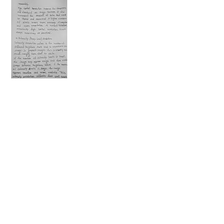

In [16]:
SAMPLE_PATCH_PATH = patch_paths[0]

sample_image = Image.open(
    SAMPLE_PATCH_PATH
).convert("RGB")

sample_image = sample_image.resize(
    (IMAGE_SIZE, IMAGE_SIZE)
)

print("Selected patch:", SAMPLE_PATCH_PATH)
print("Image dimensions:", sample_image.size)

display(sample_image)

In [17]:
def predict_tensor_batch(batch):

    model.eval()

    batch = batch.to(DEVICE)

    with torch.no_grad():
        predictions = model(batch)

    return predictions.reshape(-1, 1).cpu().numpy()


sample_tensor = preprocess_image(
    sample_image
).unsqueeze(0)

baseline_prediction = float(
    predict_tensor_batch(sample_tensor)[0, 0]
)

print("Raw EfficientNet-B0 output:", baseline_prediction)

Raw EfficientNet-B0 output: 6.72654914855957


In [6]:
# SHAP FOR EFFICIENTNET B0

In [18]:
def shap_predict(images):
    """
    Predict handwriting quality for a batch of RGB images.

    Parameters
    ----------
    images : np.ndarray
        Shape: (N, H, W, C)

    Returns
    -------
    np.ndarray
        Shape: (N, 1), containing raw model predictions.
    """

    images = np.asarray(images)

    if images.ndim == 3:
        images = images[np.newaxis, ...]

    batch_tensors = []

    for array in images:

        array = np.clip(
            array, 0, 255
        ).astype(np.uint8)

        pil_image = Image.fromarray(
            array
        ).convert("RGB")

        tensor = preprocess_image(pil_image)

        batch_tensors.append(tensor)

    batch = torch.stack(batch_tensors)

    return predict_tensor_batch(batch)


# Verify that both prediction methods agree
image_array = np.asarray(
    sample_image.convert("RGB")
)

wrapper_prediction = float(
    shap_predict(image_array[np.newaxis, ...])[0, 0]
)

print("Normal prediction:", baseline_prediction)
print("SHAP wrapper prediction:", wrapper_prediction)

assert np.isclose(
    baseline_prediction,
    wrapper_prediction,
    atol=1e-4
), (
    "Predictions do not match. "
    "Check preprocessing and model loading."
)

print("Prediction consistency check passed.")

Normal prediction: 6.72654914855957
SHAP wrapper prediction: 6.72654914855957
Prediction consistency check passed.


In [19]:
masker = shap.maskers.Image(
    "blur(32,32)",
    shape=image_array.shape
)

explainer = shap.Explainer(
    shap_predict,
    masker,
    algorithm="partition",
    output_names=["Handwriting quality"]
)

print("SHAP explainer initialized.")
print("Input image shape:", image_array.shape)

SHAP explainer initialized.
Input image shape: (224, 224, 3)


In [20]:
MAX_EVALS = 300

shap_values = explainer(
    image_array[np.newaxis, ...],
    max_evals=MAX_EVALS,
    batch_size=8
)

print("SHAP calculation completed.")
print("SHAP values shape:", shap_values.values.shape)
print("Base values:", shap_values.base_values)

  0%|          | 0/298 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:12, 12.85s/it]               

SHAP calculation completed.
SHAP values shape: (1, 224, 224, 3, 1)
Base values: [[6.59903955]]


In [21]:
values = np.asarray(
    shap_values.values
)

# Remove the sample dimension
values = values[0]

# Remove the output dimension if present
if values.ndim == 4:
    values = values[..., 0]

if values.shape != image_array.shape:
    raise ValueError(
        f"Unexpected SHAP shape: {values.shape}. "
        f"Expected: {image_array.shape}"
    )

base_value = float(
    np.asarray(
        shap_values.base_values
    ).reshape(-1)[0]
)

total_contribution = float(
    values.sum()
)

reconstructed_prediction = (
    base_value + total_contribution
)

actual_prediction = float(
    shap_predict(
        image_array[np.newaxis, ...]
    )[0, 0]
)

print("Base value:", base_value)
print("Total SHAP contribution:", total_contribution)
print("Reconstructed prediction:", reconstructed_prediction)
print("Actual model prediction:", actual_prediction)

print(
    "Absolute reconstruction difference:",
    abs(reconstructed_prediction - actual_prediction)
)

Base value: 6.599039554595947
Total SHAP contribution: 0.12750959396362288
Reconstructed prediction: 6.72654914855957
Actual model prediction: 6.72654914855957
Absolute reconstruction difference: 0.0


In [22]:
# Visualizing SHAP explanations

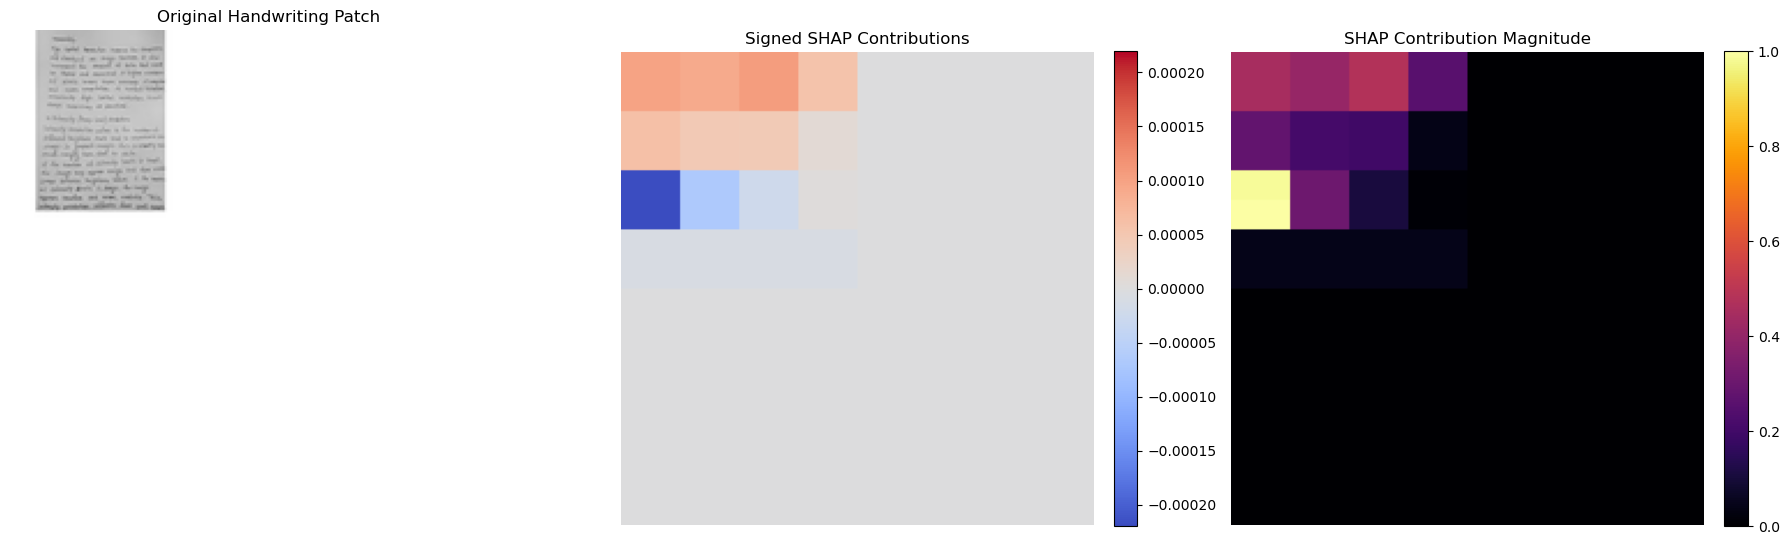

In [23]:
# Aggregate RGB channel contributions into a spatial map
signed_map = values.sum(axis=-1)

# Magnitude of the contributions
magnitude_map = np.abs(values).sum(axis=-1)

# Normalize for visualization only
magnitude_display = magnitude_map / (
    magnitude_map.max() + 1e-8
)

# Symmetric limits for the signed map
limit = max(
    float(np.max(np.abs(signed_map))),
    1e-8
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

axes[0].imshow(image_array)
axes[0].set_title("Original Handwriting Patch")

im1 = axes[1].imshow(
    signed_map,
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit
)

axes[1].set_title("Signed SHAP Contributions")

fig.colorbar(
    im1,
    ax=axes[1],
    fraction=0.046,
    pad=0.04
)

im2 = axes[2].imshow(
    magnitude_display,
    cmap="inferno",
    vmin=0,
    vmax=1
)

axes[2].set_title("SHAP Contribution Magnitude")

fig.colorbar(
    im2,
    ax=axes[2],
    fraction=0.046,
    pad=0.04
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

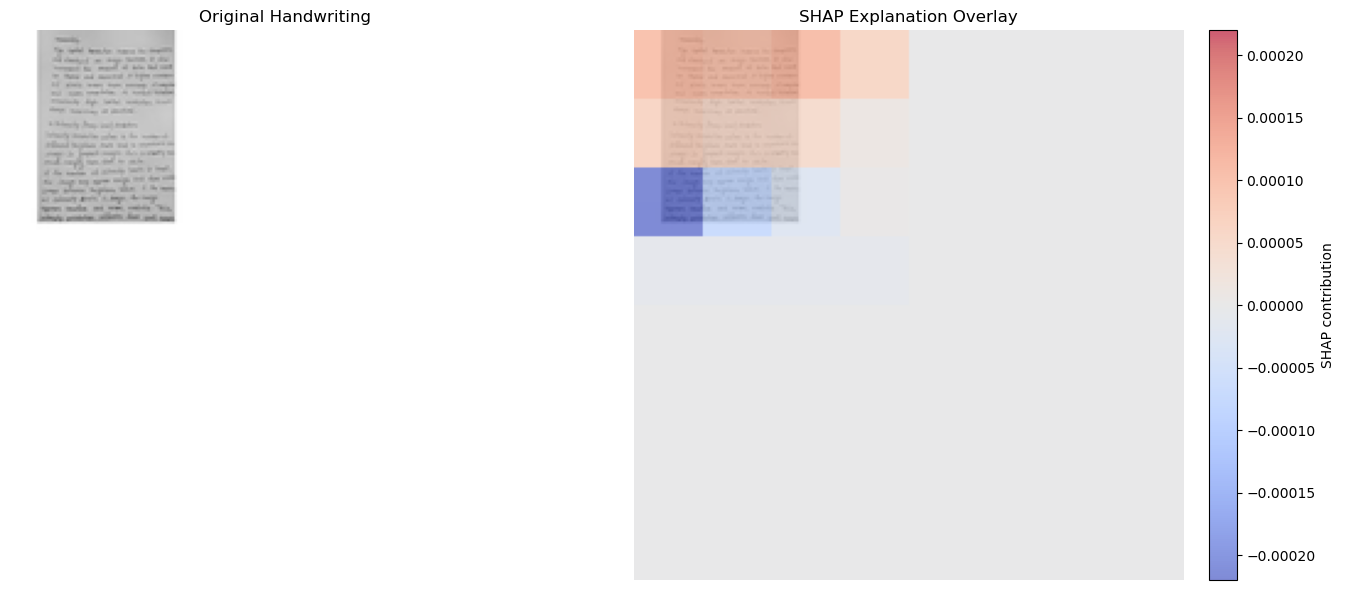

In [24]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

axes[0].imshow(image_array)
axes[0].set_title("Original Handwriting")
axes[0].axis("off")

axes[1].imshow(image_array)

heatmap = axes[1].imshow(
    signed_map,
    cmap="coolwarm",
    alpha=0.65,
    vmin=-limit,
    vmax=limit
)

axes[1].set_title("SHAP Explanation Overlay")
axes[1].axis("off")

fig.colorbar(
    heatmap,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
    label="SHAP contribution"
)

plt.tight_layout()
plt.show()

In [25]:
sample_name = SAMPLE_PATCH_PATH.stem

# Save original image
original_output = (
    OUTPUT_DIR / f"{sample_name}_original.png"
)

Image.fromarray(image_array).save(
    original_output
)

# Save signed SHAP map
signed_output = (
    OUTPUT_DIR / f"{sample_name}_signed_shap.png"
)

plt.figure(figsize=(8, 8))

plt.imshow(
    signed_map,
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit
)

plt.colorbar(label="SHAP contribution")
plt.title("Signed SHAP Contributions")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    signed_output,
    dpi=200,
    bbox_inches="tight"
)

plt.close()

# Save magnitude map
magnitude_output = (
    OUTPUT_DIR / f"{sample_name}_shap_magnitude.png"
)

plt.figure(figsize=(8, 8))

plt.imshow(
    magnitude_display,
    cmap="inferno",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Relative contribution magnitude")
plt.title("SHAP Contribution Magnitude")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    magnitude_output,
    dpi=200,
    bbox_inches="tight"
)

plt.close()

# Save overlay
overlay_output = (
    OUTPUT_DIR / f"{sample_name}_shap_overlay.png"
)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image_array)

ax.imshow(
    signed_map,
    cmap="coolwarm",
    alpha=0.65,
    vmin=-limit,
    vmax=limit
)

ax.set_title("SHAP Explanation Overlay")
ax.axis("off")

plt.tight_layout()

plt.savefig(
    overlay_output,
    dpi=200,
    bbox_inches="tight"
)

plt.close()

print("Saved explanation images:")

for path in [
    original_output,
    signed_output,
    magnitude_output,
    overlay_output
]:
    print(path)

Saved explanation images:
C:\Users\SWARA\Documents\Handwriting Analysis\xai_outputs\shap\image_1914677755536_0010be895a_patch_0000_original.png
C:\Users\SWARA\Documents\Handwriting Analysis\xai_outputs\shap\image_1914677755536_0010be895a_patch_0000_signed_shap.png
C:\Users\SWARA\Documents\Handwriting Analysis\xai_outputs\shap\image_1914677755536_0010be895a_patch_0000_shap_magnitude.png
C:\Users\SWARA\Documents\Handwriting Analysis\xai_outputs\shap\image_1914677755536_0010be895a_patch_0000_shap_overlay.png


In [26]:
# Save raw SHAP values
np.save(
    OUTPUT_DIR / f"{sample_name}_shap_values.npy",
    values
)

# Save spatial maps
np.save(
    OUTPUT_DIR / f"{sample_name}_signed_map.npy",
    signed_map
)

np.save(
    OUTPUT_DIR / f"{sample_name}_magnitude_map.npy",
    magnitude_map
)

# Save metadata
metadata = {
    "model": "EfficientNet-B0",
    "explanation_method": "SHAP Partition Explainer",
    "masker": "blur(32,32)",
    "explanation_level": "patch",
    "input_patch": str(SAMPLE_PATCH_PATH),
    "input_shape": list(image_array.shape),
    "raw_model_prediction": actual_prediction,
    "base_value": base_value,
    "sum_of_shap_values": total_contribution,
    "reconstructed_prediction": reconstructed_prediction,
    "absolute_reconstruction_difference": abs(
        reconstructed_prediction - actual_prediction
    ),
    "max_evals": MAX_EVALS,
    "generated_at": pd.Timestamp.now().isoformat()
}

metadata_path = (
    OUTPUT_DIR / f"{sample_name}_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=4)

print("Numerical SHAP values saved.")
print("Metadata saved:", metadata_path)

Numerical SHAP values saved.
Metadata saved: C:\Users\SWARA\Documents\Handwriting Analysis\xai_outputs\shap\image_1914677755536_0010be895a_patch_0000_metadata.json


In [27]:
print("SHAP OUTPUT DIRECTORY")
print("=" * 60)

for file in sorted(OUTPUT_DIR.iterdir()):

    if file.is_file():

        size_kb = file.stat().st_size / 1024

        print(
            f"{file.name:<45} "
            f"{size_kb:>8.2f} KB"
        )

SHAP OUTPUT DIRECTORY
image_1914677755536_0010be895a_patch_0000_magnitude_map.npy   392.12 KB
image_1914677755536_0010be895a_patch_0000_metadata.json     0.68 KB
image_1914677755536_0010be895a_patch_0000_original.png     7.70 KB
image_1914677755536_0010be895a_patch_0000_shap_magnitude.png    45.61 KB
image_1914677755536_0010be895a_patch_0000_shap_overlay.png    36.50 KB
image_1914677755536_0010be895a_patch_0000_shap_values.npy  1176.12 KB
image_1914677755536_0010be895a_patch_0000_signed_map.npy   392.12 KB
image_1914677755536_0010be895a_patch_0000_signed_shap.png    59.32 KB
